In [49]:
# Importo las librerias
import math
import sympy as sp
import numpy as np
import pandas as pd
import scipy.signal as sig
import matplotlib.pyplot as plt
from sympy import Eq
from IPython.display import display, IFrame, Math
from matplotlib import pyplot as plt
from scipy.signal import TransferFunction
from scipy.interpolate import make_interp_spline
from matplotlib.ticker import MaxNLocator

# Función para mostrar en formato de ingenieria las unidades
def eng_format(value, unit=""):
    import numpy as np
    if value == 0:
        return f"0 {unit}"
    exp = int(np.floor(np.log10(abs(value)) / 3) * 3)
    scaled = value / (10**exp)
    prefixes = {-12: "p",-9: "n",-6: "u",-3: "m",0: "",3: "k",6: "M",9: "G"}
    prefix = prefixes.get(exp, f"e{exp}")
    return f"{scaled:.1f} {prefix}{unit}"

#--------------------------------------------------------------------------

str


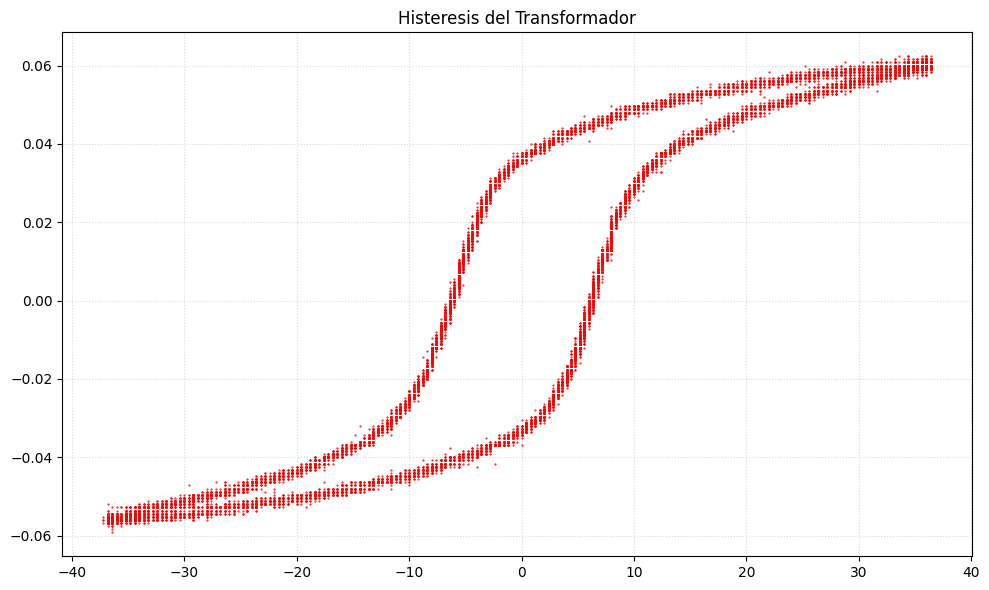

In [73]:
# Gráfico hecho con el archivo HIST.csv medido en el laboratorio con el Analizador de Audio:
datos = pd.read_csv('HIST.csv', skiprows=0)

Chanel_1 = pd.to_numeric(datos['CH1'][1:])
Chanel_2 = pd.to_numeric(datos['CH2'][1:])

print(datos['CH1'].dtype)

plt.figure(figsize=(10, 6))
plt.title('Histeresis del Transformador')

plt.plot(
    Chanel_1, Chanel_2,
    color='red',
    marker='.',
    markersize=1 ,
    linestyle='',
    linewidth=1 
#    label='Histeresis del Transformador'
)

'''
linestyle
    ls='-'
    ls='--'
    ls='-.'
    ls=':'

marker
    marker='o'    # círculo
    marker='.'    # punto
    marker='x'    # x
    marker='+'    # +
    marker='s'    # cuadrado
    marker='^'    # triángulo
    marker='*'    # estrella
'''

# plt.title('Respuesta en frecuencia', fontsize=16, fontweight='bold')
# plt.xlabel('Frecuencia [Hz]', fontsize=12, fontweight='bold')
# plt.ylabel('Magnitud [dB]', fontsize=12, fontweight='bold')

# plt.xlim(0, 1000)
# plt.ylim(-60, 5)
# plt.xscale('log')
# plt.yscale('log')

# marcador_1 = Chanel_1[Chanel_2.index(0)]
# marcador_2 = Chanel_2[Chanel_1.index(0)]
# plt.axhline(marcador_1, linestyle='--', alpha=0.7)
# plt.axvline(marcador_2, linestyle='--', alpha=0.7)

'''
#-----------------------------------------------------------------------
# Índice donde CH1 vale 0
indices_x0 = Chanel_1[Chanel_1 == 0].index
marcador_2 = Chanel_2.loc[indices_x0]

# Índice donde CH2 vale 0
indice_y0 = Chanel_2[Chanel_2 == 0].index
marcador_1 = Chanel_1.loc[indice_y0]

for x in marcador_2:
    plt.axhline(x, linestyle=':', alpha=0.03)
for y in marcador_1:
    plt.axvline(y, linestyle=':', alpha=0.03)
#-----------------------------------------------------------------------
'''
# plt.annotate(
#     'Frecuencia de corte',
#     xy=(2, -3),
#     xytext=(2*2, -10),
#     arrowprops=dict(arrowstyle='->')
# )

plt.grid( True, linestyle=':', alpha=0.5)
# plt.legend(loc='best', fontsize=10)
'''
posiciones
    loc='upper right'
    loc='upper left'
    loc='lower right'
    loc='lower left'
    loc='center'
'''

# plt.gca().xaxis.set_major_locator(MaxNLocator(8))
# plt.gca().yaxis.set_major_locator(MaxNLocator(6))


plt.tight_layout()
plt.show()

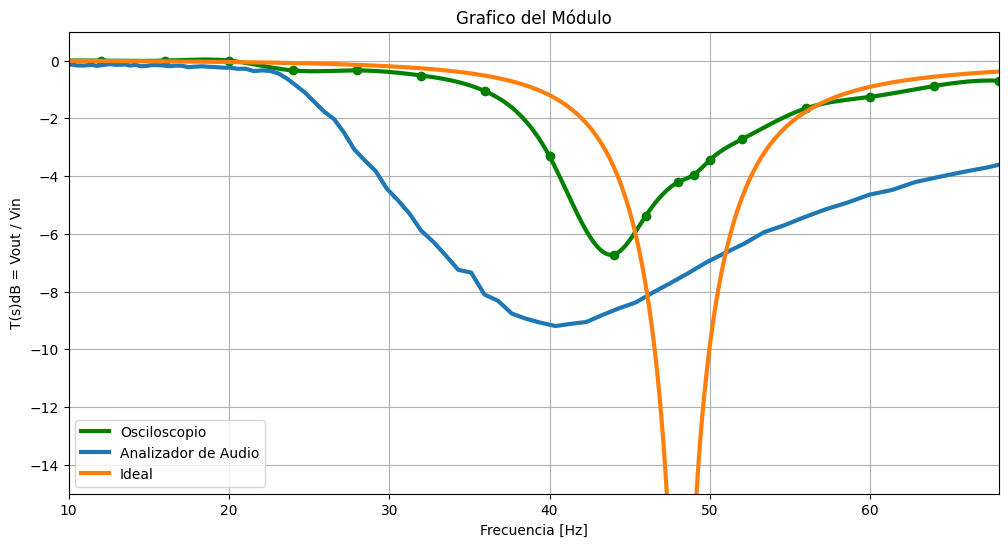

In [26]:
# ----------------------------
# -----  Gráfico 1: ----------
#-----------------------------
    # Gráfico hecho con las mediciones del Osciloscopio
# Datos:
frecuencia_1 = np.array([ 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 46, 48, 49, 50, 52, 56, 60, 64, 68 ])
Vout = np.array([ 520, 520, 520, 520, 520, 500, 500, 490, 460, 355, 240, 280, 320, 330, 350, 380, 430, 450, 470, 480])
Vin = 520  # mV

# Transferencia punto a punto
H = 20*np.log10(Vout / Vin)

# Curva suave
f_suave = np.linspace(frecuencia_1.min(), frecuencia_1.max(), 500)
H_suave = make_interp_spline(frecuencia_1, H)(f_suave)

plt.figure(figsize=(12, 6))

plt.plot(frecuencia_1, H, 'o', color='green')
plt.plot(f_suave, H_suave, color='green', label='Osciloscopio', lw=3)

# ----------------------------
# -----  Gráfico 2: ----------
#-----------------------------
    # Gráfico hecho con el archivo modulo.csv medido en el laboratorio con el Analizador de Audio
datos = pd.read_csv('modulo.csv', skiprows=2)

frecuencia_2 = datos['X (Hz)']
H_dB = datos['Ch-1 (dBr)']

plt.plot(frecuencia_2, H_dB, label='Analizador de Audio', lw=3)

# ----------------------------
# -----  Gráfico 3: ----------
#-----------------------------
    # Gráfico de comportamiendo ideal con nuestros componentes del módulo:
# Datos:
num = [ 1 , 0 , 9.183e4 ]
den = [ 1 , 64.28 , 9.183e4 ]

# Transferencia
H = TransferFunction(num, den)
frecuencia_3 = np.linspace(4, 68, 500)

# Respuesta en frecuencia del módulo
_, H = H.freqresp(2 * np.pi * frecuencia_3)
H_dB = 20 * np.log10(np.abs(H))

plt.plot(frecuencia_3, H_dB, label='Ideal', lw=3)

plt.title('Grafico del Módulo')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('T(s)dB = Vout / Vin')
plt.xlim(10, 68)
plt.ylim(-15, 1)
plt.grid()
plt.legend()
plt.show()

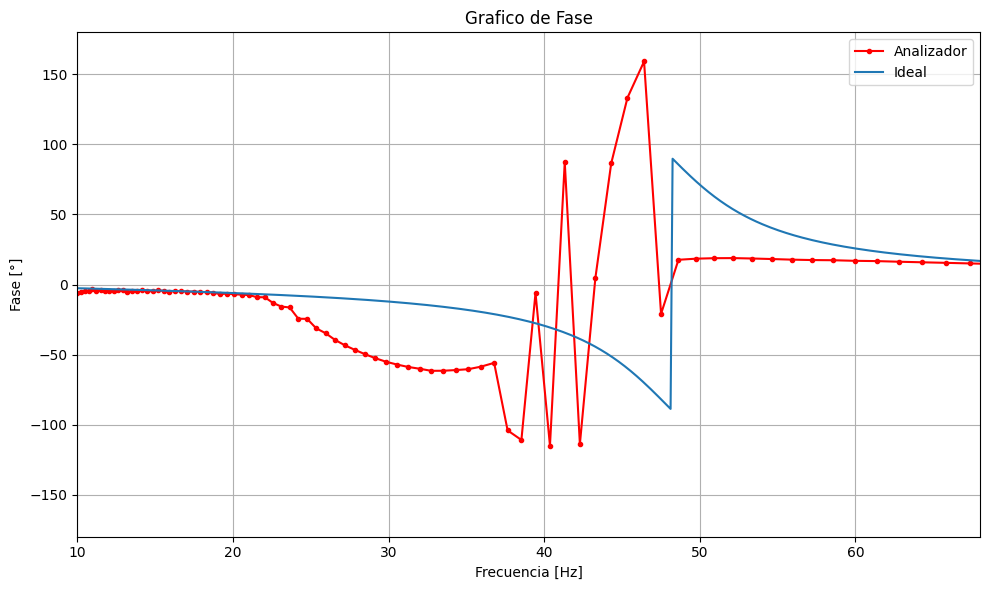

In [25]:
# ----------------------------
# -----  Gráfico 1: ----------
#-----------------------------
    # Gráfico hecho con el archivo fase.csv medido en el laboratorio con el Analizador de Audio:
datos = pd.read_csv('fase.csv', skiprows=2)

frecuencia = datos['X (Hz)']
Psi = datos['Ch-1 ']

plt.figure(figsize=(10, 6))
plt.plot(frecuencia, Psi, color='red', marker='.', linestyle='-', label='Analizador')

# ----------------------------
# -----  Gráfico 2: ----------
#-----------------------------
    # Gráfico de comportamiendo ideal con nuestros componentes de la fase:
# Datos:
num = [ 1 , 0 , 9.183e4 ]
den = [ 1 , 64.28 , 9.183e4 ]

# Transferencia
H = TransferFunction(num, den)
frecuencia = np.linspace(4, 68, 500)

# Respuesta en frecuencia de la fase en grados
_, H = H.freqresp(2 * np.pi * frecuencia)
fase = np.angle(H, deg=True)

plt.plot(frecuencia, fase, label='Ideal')

# ----------------------------
plt.title('Grafico de Fase')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Fase [°]')
plt.xlim(10, 68)
plt.ylim(-180, 180)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()